# Segmentación de Clientes y Diseño de Campañas de Marketing
En este proyecto se busca realizar una segmentación de clientes de un negocio tipo e-commerce utilizando técnicas de clustering, específicamente el algoritmo K-Means.

El objetivo principal es identificar grupos de clientes con características similares para poder entender mejor su comportamiento de compra y así apoyar la toma de decisiones estratégicas en marketing.

Esto permite generar perfiles más precisos y personalizados, ya que el comportamiento de compra puede variar significativamente entre distintos grupos demográficos.

Finalmente, se evaluarán relaciones entre variables mediante análisis de correlación y visualizaciones como mapas de calor, con el fin de entender qué factores influyen más en la formación de los clusters.

El problema que se aborda es de tipo no supervisado, ya que no se cuenta con etiquetas previas que indiquen a qué grupo pertenece cada cliente.

Por lo tanto, se utilizarán algoritmos de clustering para descubrir patrones ocultos en los datos.

En términos de negocio, este análisis permite responder preguntas como:

* ¿Qué tipos de clientes existen?
* ¿Cuáles tienen mayor ingreso y gasto?
* ¿Existen grupos bien diferenciados que permitan crear campañas específicas?

Este tipo de segmentación es ampliamente utilizado en marketing para mejorar la personalización, aumentar ventas y optimizar recursos.

In [1]:
import pandas as pd
import numpy as np

In [2]:
Datos = pd.read_csv("Mall_Customers.csv", on_bad_lines='skip')
#Creamos la copia para trabajar mejor
df = Datos.copy()
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.shape

(200, 5)

In [4]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [6]:
#datos faltan en cada columna
df.isna().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [7]:
# Ver información general del dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [8]:
df.nunique()

CustomerID                200
Gender                      2
Age                        51
Annual Income (k$)         64
Spending Score (1-100)     84
dtype: int64

In [9]:
df.drop_duplicates()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


En esta etapa se busca comprender el significado de cada una de las variables del dataset, así como su tipo de dato y su posible utilidad dentro del análisis.

El conjunto de datos contiene información básica de clientes de un centro comercial, incluyendo características demográficas y un indicador de comportamiento de consumo.

Para facilitar la interpretación del análisis, se realizará una traducción de los nombres de las variables al español, permitiendo una lectura más intuitiva y clara del contenido del dataset.

In [10]:
# Ver las columnas originales
print("Columnas originales:")
print(df.columns)

Columnas originales:
Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')


In [11]:
# Renombrar columnas al español
df.rename(columns={
    'CustomerID': 'ID_Cliente',
    'Gender': 'Genero',
    'Age': 'Edad',
    'Annual Income (k$)': 'Ingreso_Anual_k$',
    'Spending Score (1-100)': 'Puntaje_Gasto'
}, inplace=True)

In [12]:
# Ver las nuevas columnas
print("\nColumnas renombradas:")
print(df.columns)


Columnas renombradas:
Index(['ID_Cliente', 'Genero', 'Edad', 'Ingreso_Anual_k$', 'Puntaje_Gasto'], dtype='str')


In [13]:
# Mostrar primeras filas para verificar cambios
df.head()

,ID_Cliente,Genero,Edad,Ingreso_Anual_k$,Puntaje_Gasto
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


A continuación se describe el significado de cada variable presente en el dataset:

* ID_Cliente: Identificador único de cada cliente.
* Genero: Sexo del cliente (Male o Female).
* Edad: Edad del cliente en años.
* Ingreso_Anual_k$: Ingreso anual del cliente expresado en miles de dólares.
* Puntaje_Gasto: Indicador asignado por el negocio que refleja el nivel de gasto del cliente en una escala de 1 a 100.

Estas variables permiten analizar tanto características demográficas como comportamientos de consumo, lo cual es fundamental para realizar una segmentación efectiva.

In [14]:
# fILtramos solo clientas mujeres
df_mujeres = df[df['Genero'] == 'Female']

In [15]:
df_mujeres.head()

,ID_Cliente,Genero,Edad,Ingreso_Anual_k$,Puntaje_Gasto
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6


In [16]:
# fILtramos ahora a loa hombres
df_hombres = df[df['Genero'] == 'Male']

In [17]:
df_hombres.head()

,ID_Cliente,Genero,Edad,Ingreso_Anual_k$,Puntaje_Gasto
0,1,Male,19,15,39
1,2,Male,21,15,81
8,9,Male,64,19,3
10,11,Male,67,19,14
14,15,Male,37,20,13


## ¿Qué son las estadísticas descriptivas?

Las **estadísticas descriptivas** nos ayudan a resumir y entender un conjunto de datos. Por ejemplo, si tenemos información de muchos clientes, podemos saber cuánto gastan normalmente, qué tan diferentes son sus compras y cuáles son los valores más altos y más bajos.

Al usar `describe()` en Python, aparecen las siguientes estadísticas:

| Estadística | ¿Qué representa? |
|---|---|
| **count (cantidad)** | Cuántos datos hay registrados, sin contar los valores vacíos. | Si hay 100 clientes con su edad registrada, el resultado es 100. |
| **mean (promedio)** | Se suman todos los valores y se dividen entre la cantidad de datos. |
| **std (desviación estándar)** | Indica qué tan separados están los datos del promedio. Un valor pequeño significa que son parecidos; uno grande, que hay más diferencias. |
| **min (mínimo)** | Es el valor más pequeño que encontramos. |
| **25% (primer cuartil)** | Es el valor que marca aproximadamente el primer 25% de los datos cuando se ordenan de menor a mayor. |
| **50% (mediana)** | Es el valor que queda en medio al ordenar los datos. Si hay dos valores centrales, se calcula su promedio. |
| **75% (tercer cuartil)** | Es el valor que marca aproximadamente el primer 75% de los datos ordenados. |
| **max (máximo)** | Es el valor más grande que encontramos. |


### ¿Para qué sirven en este proyecto?

Estas estadísticas nos permiten conocer cómo son nuestros clientes antes de crear el modelo de aprendizaje automático (**ML**). Nos ayudan a identificar comportamientos comunes, diferencias entre clientes y valores que conviene revisar.

**Ojo:** el promedio y la mediana no siempre son iguales. Una compra muy grande puede subir mucho el promedio, mientras que la mediana cambia menos.

In [18]:
# Estadísticas del dataset completo
print("Resumen estadístico - Dataset completo")
print(df.describe())

Resumen estadístico - Dataset completo
       ID_Cliente        Edad  Ingreso_Anual_k$  Puntaje_Gasto
count  200.000000  200.000000        200.000000     200.000000
mean   100.500000   38.850000         60.560000      50.200000
std     57.879185   13.969007         26.264721      25.823522
min      1.000000   18.000000         15.000000       1.000000
25%     50.750000   28.750000         41.500000      34.750000
50%    100.500000   36.000000         61.500000      50.000000
75%    150.250000   49.000000         78.000000      73.000000
max    200.000000   70.000000        137.000000      99.000000


In [19]:
# Estadísticas solo para mujeres
print("Resumen estadístico - Mujeres")
print(df_mujeres.describe())

Resumen estadístico - Mujeres
       ID_Cliente        Edad  Ingreso_Anual_k$  Puntaje_Gasto
count  112.000000  112.000000        112.000000     112.000000
mean    97.562500   38.098214         59.250000      51.526786
std     58.276412   12.644095         26.011952      24.114950
min      3.000000   18.000000         16.000000       5.000000
25%     46.750000   29.000000         39.750000      35.000000
50%     94.500000   35.000000         60.000000      50.000000
75%    148.250000   47.500000         77.250000      73.000000
max    197.000000   68.000000        126.000000      99.000000


In [20]:
# Estadísticas solo para hombres
print("Resumen estadístico - Hombres")
print(df_hombres.describe())

Resumen estadístico - Hombres
       ID_Cliente       Edad  Ingreso_Anual_k$  Puntaje_Gasto
count   88.000000  88.000000         88.000000      88.000000
mean   104.238636  39.806818         62.227273      48.511364
std     57.483830  15.514812         26.638373      27.896770
min      1.000000  18.000000         15.000000       1.000000
25%     59.500000  27.750000         45.500000      24.500000
50%    106.500000  37.000000         62.500000      50.000000
75%    151.250000  50.500000         78.000000      70.000000
max    200.000000  70.000000        137.000000      97.000000


## Analisis Univariado

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
# Configuración de estilo de gráficas
sns.set(style="whitegrid")

In [23]:
# Crear figura
plt.figure(figsize=(15,5))

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

Text(0.5, 1.0, 'Distribución de Edad')

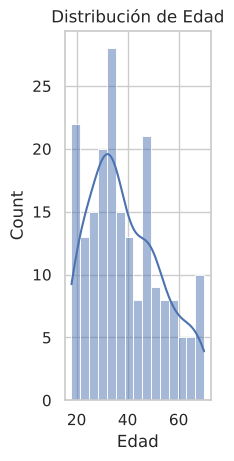

In [24]:
# Histograma Edad
plt.subplot(1,3,1)
sns.histplot(df['Edad'], bins=15, kde=True)
plt.title('Distribución de Edad')

Text(0.5, 1.0, 'Distribución de Ingreso Anual')

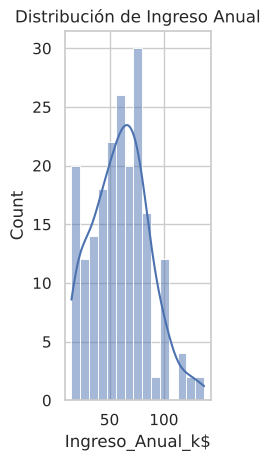

In [25]:
# Histograma Ingreso
plt.subplot(1,3,2)
sns.histplot(df['Ingreso_Anual_k$'], bins=15, kde=True)
plt.title('Distribución de Ingreso Anual')

Text(0.5, 1.0, 'Distribución de Puntaje de Gasto')

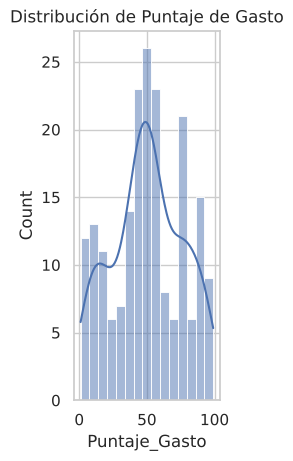

In [26]:
# Histograma Puntaje de Gasto
plt.subplot(1,3,3)
sns.histplot(df['Puntaje_Gasto'], bins=15, kde=True)
plt.title('Distribución de Puntaje de Gasto')

In [27]:
# Mostrar gráficas
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [28]:
import matplotlib.pyplot as plt

In [29]:
# Contar clientes por género y traducir las etiquetas
conteo = df['Genero'].replace({
    'Female': 'Mujeres',
    'Male': 'Hombres'
}).value_counts()

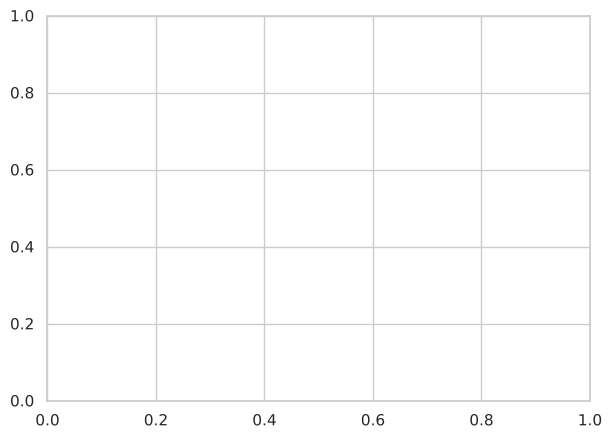

In [30]:
fig, ax = plt.subplots(figsize=(7, 5))

In [31]:
barras = ax.bar(
    conteo.index,
    conteo.values,
    color=['#56B4E9', '#E69F00'],
    width=0.55
)

In [32]:
# Mostrar la cantidad y el porcentaje sobre cada barra
etiquetas = [
    f'{cantidad} ({cantidad / conteo.sum():.1%})'
    for cantidad in conteo.values
]
ax.bar_label(barras, labels=etiquetas, padding=5)

[Text(0, 5, '112 (56.0%)'), Text(0, 5, '88 (44.0%)')]

In [33]:
ax.set_title('Distribución de clientes por género')
ax.set_xlabel('Género')
ax.set_ylabel('Cantidad de clientes')
ax.set_ylim(0, conteo.max() * 1.15)

(0.0, 128.79999999999998)

In [34]:
# Mostrar solo números enteros en el eje vertical
from matplotlib.ticker import MaxNLocator
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

In [35]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [36]:
plt.figure(figsize=(15,5))

<Figure size 1500x500 with 0 Axes>

<Figure size 1500x500 with 0 Axes>

Text(0.5, 1.0, 'Boxplot Edad')

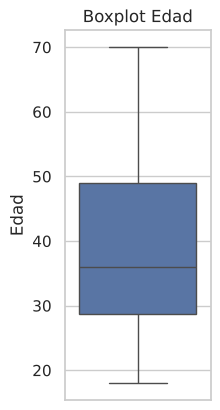

In [37]:
# Edad
plt.subplot(1,3,1)
sns.boxplot(y=df['Edad'])
plt.title('Boxplot Edad')

Text(0.5, 1.0, 'Boxplot Ingreso Anual')

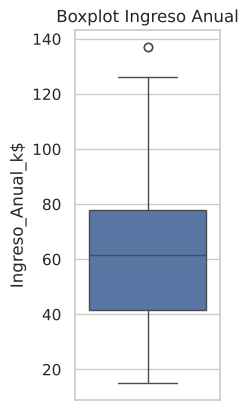

In [38]:
# Ingreso
plt.subplot(1,3,2)
sns.boxplot(y=df['Ingreso_Anual_k$'])
plt.title('Boxplot Ingreso Anual')

Text(0.5, 1.0, 'Boxplot Puntaje de Gasto')

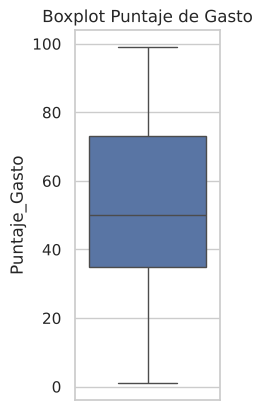

In [39]:
# Puntaje de gasto
plt.subplot(1,3,3)
sns.boxplot(y=df['Puntaje_Gasto'])
plt.title('Boxplot Puntaje de Gasto')

In [40]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

## Analisis Bivariado

In [41]:
plt.figure(figsize=(6,5))

<Figure size 600x500 with 0 Axes>

<Figure size 600x500 with 0 Axes>

<Axes: xlabel='Edad', ylabel='Puntaje_Gasto'>

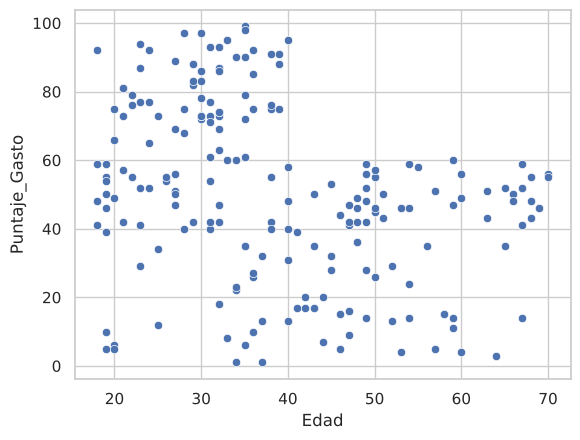

In [42]:
sns.scatterplot(
    x=df['Edad'],
    y=df['Puntaje_Gasto']
)

Text(0, 0.5, 'Puntaje de Gasto')

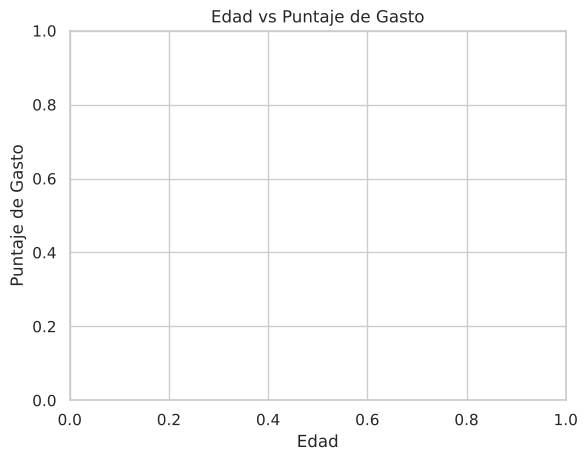

In [43]:
plt.title('Edad vs Puntaje de Gasto')
plt.xlabel('Edad')
plt.ylabel('Puntaje de Gasto')

In [44]:
plt.show()

In [45]:
plt.figure(figsize=(6,5))

<Figure size 600x500 with 0 Axes>

<Figure size 600x500 with 0 Axes>

<Axes: xlabel='Ingreso_Anual_k$', ylabel='Puntaje_Gasto'>

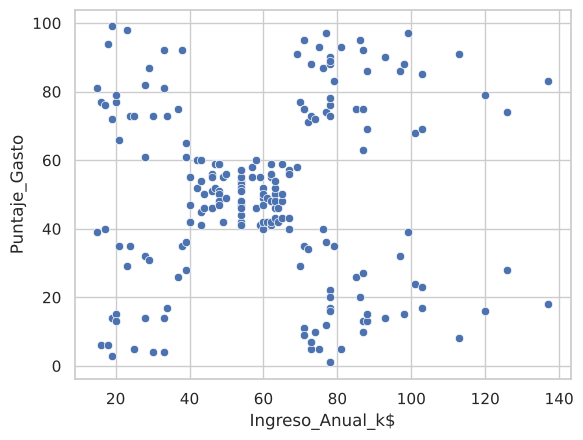

In [46]:
sns.scatterplot(
    x=df['Ingreso_Anual_k$'],
    y=df['Puntaje_Gasto']
)

Text(0, 0.5, 'Puntaje de Gasto')

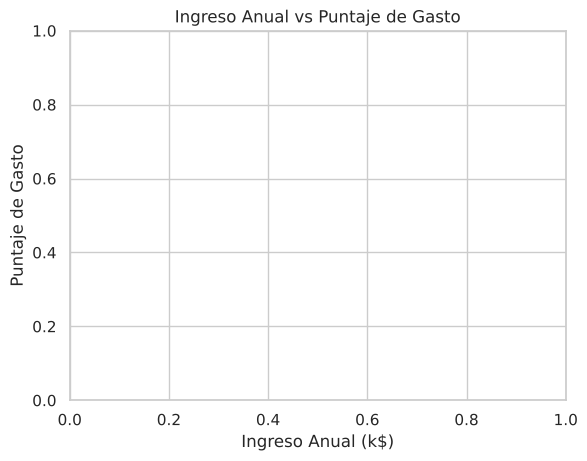

In [47]:
plt.title('Ingreso Anual vs Puntaje de Gasto')
plt.xlabel('Ingreso Anual (k$)')
plt.ylabel('Puntaje de Gasto')

In [48]:
plt.show()

In [49]:
plt.figure(figsize=(6,5))

<Figure size 600x500 with 0 Axes>

<Figure size 600x500 with 0 Axes>

<Axes: xlabel='Edad', ylabel='Ingreso_Anual_k$'>

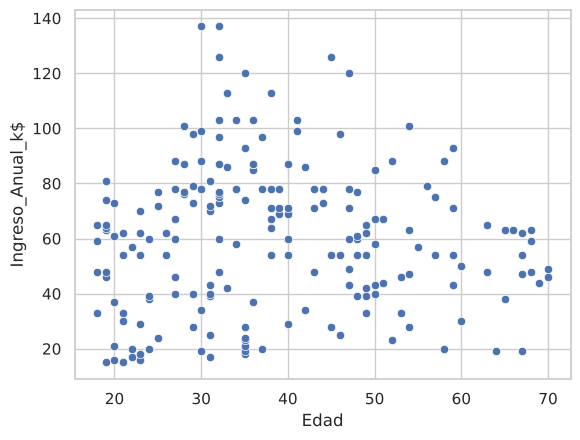

In [50]:
sns.scatterplot(
    x=df['Edad'],
    y=df['Ingreso_Anual_k$']
)

Text(0, 0.5, 'Ingreso Anual (k$)')

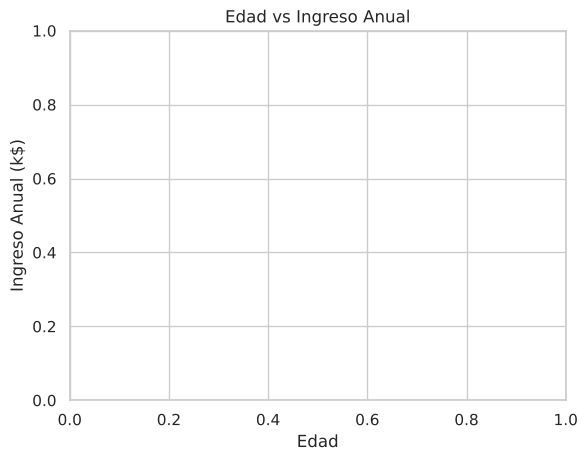

In [51]:
plt.title('Edad vs Ingreso Anual')
plt.xlabel('Edad')
plt.ylabel('Ingreso Anual (k$)')

In [52]:
plt.show()

In [53]:
plt.figure(figsize=(7,6))

<Figure size 700x600 with 0 Axes>

<Figure size 700x600 with 0 Axes>

<Axes: xlabel='Edad', ylabel='Ingreso_Anual_k$'>

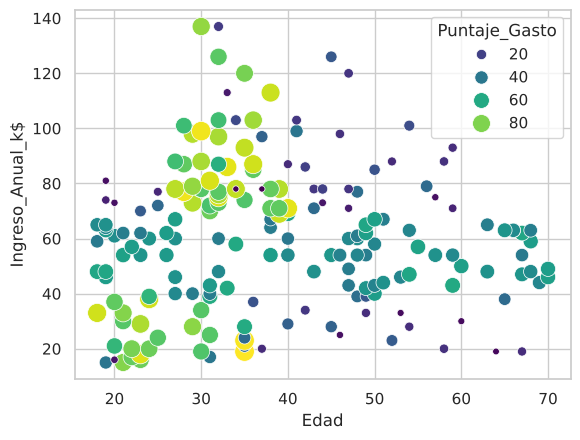

In [54]:
sns.scatterplot(
    x=df['Edad'],
    y=df['Ingreso_Anual_k$'],
    hue=df['Puntaje_Gasto'],
    palette='viridis',
    size=df['Puntaje_Gasto'],
    sizes=(20, 200)
)

Text(0, 0.5, 'Ingreso Anual (k$)')

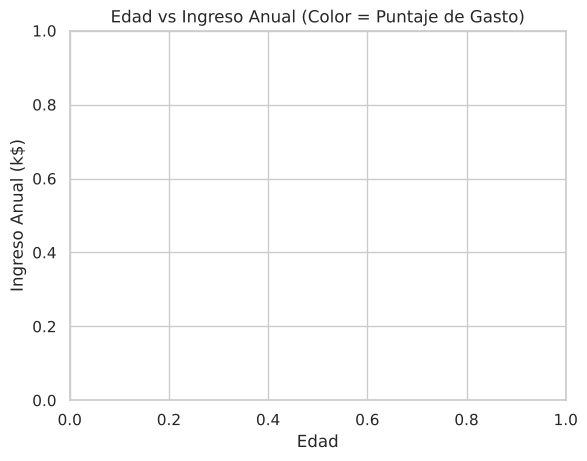

In [55]:
plt.title('Edad vs Ingreso Anual (Color = Puntaje de Gasto)')
plt.xlabel('Edad')
plt.ylabel('Ingreso Anual (k$)')

/tmp/ipykernel_428/3976425859.py:1: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Puntaje de Gasto', bbox_to_anchor=(1.05, 1))


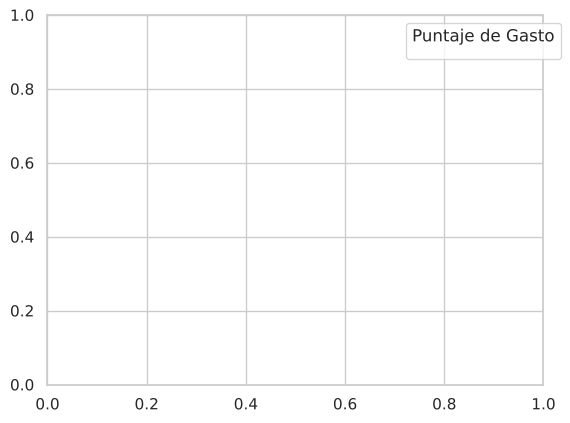

In [56]:
plt.legend(title='Puntaje de Gasto', bbox_to_anchor=(1.05, 1))
plt.show()

In [57]:
import plotly.graph_objects as go

In [58]:
fig = go.Figure(go.Scatter3d(
    x=df['Edad'],
    y=df['Ingreso_Anual_k$'],
    z=df['Puntaje_Gasto'],
    mode='markers',
    marker=dict(size=5, color='steelblue', opacity=0.75),
    showlegend=False,
    hovertemplate=(
        'Edad: %{x} años<br>'
        'Ingreso anual: %{y} mil dólares<br>'
        'Puntaje de gasto: %{z}'
        '<extra></extra>'
    )
))

In [59]:
fig.update_layout(
    title='Edad, ingreso anual y puntaje de gasto',
    scene=dict(
        xaxis_title='Edad (años)',
        yaxis_title='Ingreso anual (miles de dólares)',
        zaxis_title='Puntaje de gasto'
    ),
    margin=dict(l=0, r=0, b=0, t=50),
    height=650
)

In [60]:
fig.show()

In [61]:
# Función para detectar outliers usando IQR
def detectar_outliers(df, columna):
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[(df[columna] < limite_inferior) | (df[columna] > limite_superior)]

    return outliers

In [62]:
# Aplicar a cada variable
outliers_edad = detectar_outliers(df, 'Edad')
outliers_ingreso = detectar_outliers(df, 'Ingreso_Anual_k$')
outliers_gasto = detectar_outliers(df, 'Puntaje_Gasto')

In [63]:
# Mostrar resultados
print("Outliers en Edad:", len(outliers_edad))
print("Outliers en Ingreso:", len(outliers_ingreso))
print("Outliers en Gasto:", len(outliers_gasto))

Outliers en Edad: 0
Outliers en Ingreso: 2
Outliers en Gasto: 0


## Correlaciones

El análisis de correlación permite medir el grado de relación entre dos variables numéricas.

Su valor oscila entre -1 y 1:

* 1 :correlación positiva perfecta (ambas variables aumentan juntas)
* 0 : no existe relación
* -1 : correlación negativa perfecta (una aumenta mientras la otra disminuye)

In [64]:
# Seleccionamos las variables numericas
df_num = df[['Edad', 'Ingreso_Anual_k$', 'Puntaje_Gasto']]

In [65]:
# Calcular correlación
corr_pearson = df_num.corr(method='pearson')

<Axes: >

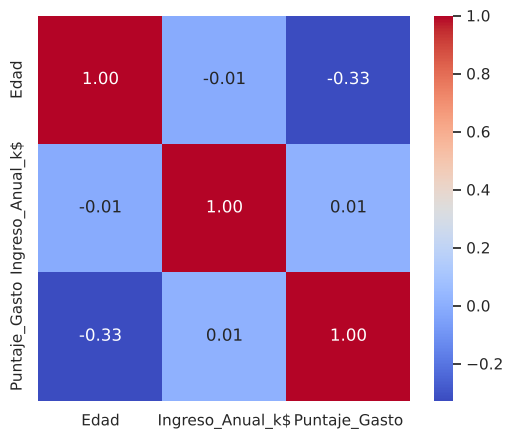

In [66]:
# Graficar mapa de calor
plt.figure(figsize=(6,5))
sns.heatmap(corr_pearson, annot=True, cmap='coolwarm', fmt=".2f")

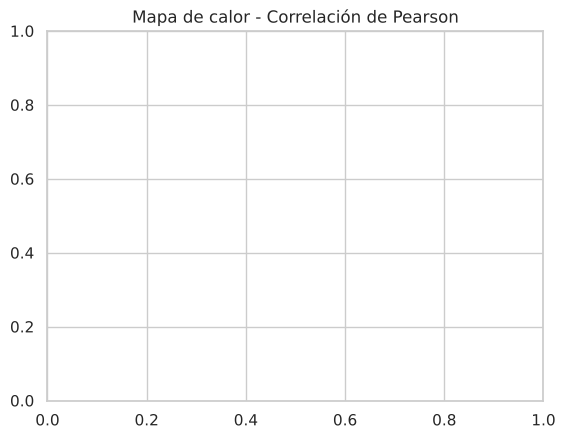

In [67]:
plt.title('Mapa de calor - Correlación de Pearson')
plt.show()

La correlación de Pearson mide la relación lineal entre variables.

Valores cercanos a 1 o -1 indican una relación fuerte, mientras que valores cercanos a 0 indican poca o ninguna relación lineal.

En este dataset, es común observar que la relación entre ingreso anual y puntaje de gasto no es estrictamente lineal, lo cual sugiere que pueden existir patrones más complejos que no son capturados completamente por esta métrica.

In [68]:
corr_spearman = df_num.corr(method='spearman')

<Axes: >

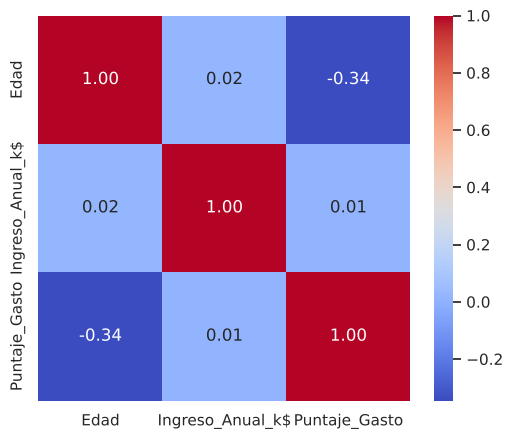

In [69]:
plt.figure(figsize=(6,5))
sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', fmt=".2f")

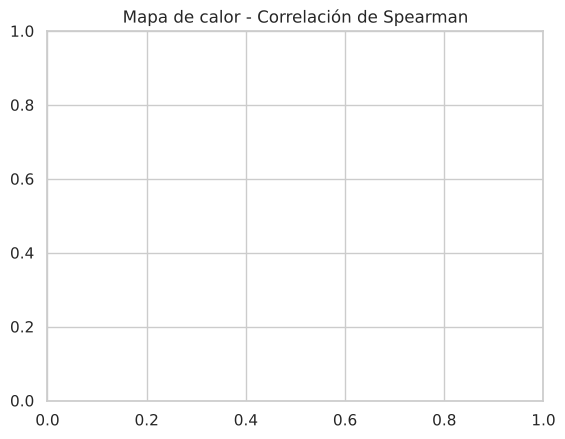

In [70]:
plt.title('Mapa de calor - Correlación de Spearman')
plt.show()

La correlación de Spearman evalúa relaciones monótonas, es decir, cuando una variable tiende a aumentar o disminuir consistentemente con otra, aunque no exista una relación lineal directa.

Esto es útil en datasets donde las relaciones pueden ser curvas o no lineales, como suele ocurrir en datos de comportamiento de clientes.

Comparar Pearson y Spearman permite identificar si existen relaciones ocultas que no son evidentes de forma lineal.

In [71]:
corr_kendall = df_num.corr(method='kendall')

<Axes: >

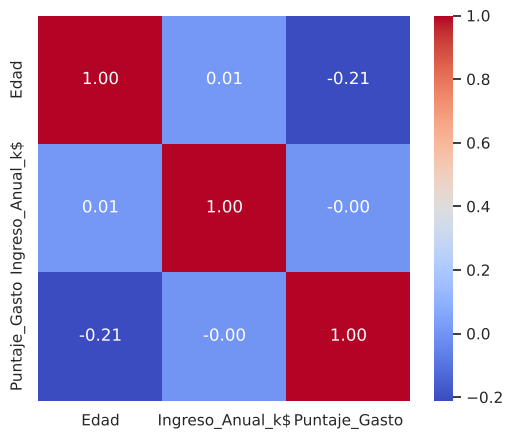

In [72]:
plt.figure(figsize=(6,5))
sns.heatmap(corr_kendall, annot=True, cmap='coolwarm', fmt=".2f")

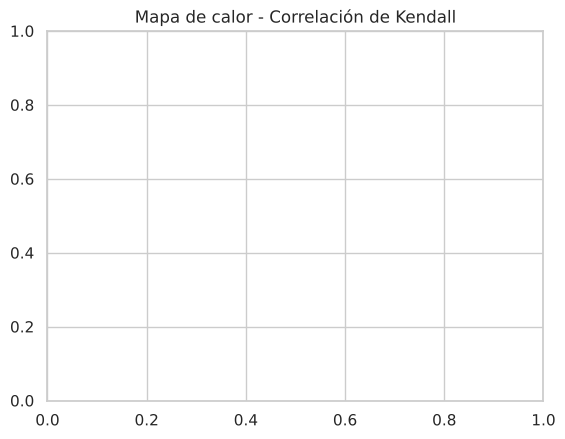

In [73]:
plt.title('Mapa de calor - Correlación de Kendall')
plt.show()

La correlación de Kendall mide la concordancia entre pares de observaciones, evaluando si el orden relativo entre los datos se mantiene entre variables.

Es una medida más robusta frente a valores atípicos y útil cuando se desea analizar relaciones basadas en rankings.

Aunque suele ser más conservadora que Pearson y Spearman, proporciona una visión adicional sobre la estructura de los datos.

## Preprocesamiento de Datos

In [74]:
# Seleccionamos variables numéricas relevantes
X = df[['Edad', 'Ingreso_Anual_k$', 'Puntaje_Gasto']]

In [75]:
X.head()

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [76]:
from sklearn.preprocessing import MinMaxScaler

In [77]:
# Crear el normalizador
scaler = MinMaxScaler()

In [78]:
# Aplicar transformación
X_norm = scaler.fit_transform(X)

In [79]:
# Convertir a DataFrame
X_norm = pd.DataFrame(X_norm, columns=X.columns)

In [80]:
# Mostrar primeras filas
X_norm.head()

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
0,0.019231,0.000000,0.387755
1,0.057692,0.000000,0.816327
2,0.038462,0.008197,0.051020
3,0.096154,0.008197,0.775510
4,0.250000,0.016393,0.397959


## ¿Qué es el método del codo y cómo se usa?

El **método del codo** nos ayuda a elegir cuántos grupos formar con **K-Means**, un algoritmo que junta datos parecidos. A esa cantidad de grupos la llamamos **K**.

Imagina que queremos organizar a los clientes de una tienda según su edad, ingreso y puntaje de gasto. Podemos probar con 2, 3, 4 o más grupos, pero necesitamos decidir cuántos tienen sentido.

### ¿Qué es la inercia?

Cada grupo tiene un centro llamado **centroide**, que representa el promedio de los datos de ese grupo.

La **inercia** mide qué tan lejos están los datos del centro de su grupo. Para calcularla, K-Means eleva al cuadrado la distancia de cada dato a su centro y suma los resultados.

Piensa en varios equipos reunidos alrededor de sus capitanes:

- Si los integrantes están cerca de su capitán, la **inercia es baja**.
- Si están muy separados de él, la **inercia es alta**.

Una inercia baja indica grupos más compactos. Sin embargo, **no significa por sí sola que elegimos la mejor cantidad de grupos**: al agregar más grupos, la inercia normalmente disminuye. Si cada dato tuviera su propio grupo, sería cero.

### ¿Cómo se usa el método del codo?

1. Probamos K-Means con distintas cantidades de grupos, por ejemplo, de **1 a 10**.
2. Registramos la inercia obtenida para cada cantidad.
3. Hacemos una gráfica con la **cantidad de grupos en el eje horizontal** y la **inercia en el eje vertical**.
4. Buscamos un punto donde la curva deje de bajar mucho y empiece a bajar más lentamente. Ese cambio de dirección se parece a un **codo**.

Por ejemplo, si pasar de 2 a 3 grupos reduce mucho la inercia, pero pasar de 3 a 4 apenas la reduce, **3 grupos podría ser una buena elección**.

### ¿Qué debemos tener en cuenta?

Antes de aplicar el método, conviene poner las variables en escalas comparables para que una no tenga más influencia solo por usar números más grandes.

El codo es una **pista**, no una respuesta exacta. A veces no se ve claramente; por eso también debemos revisar si los grupos tienen sentido y apoyarnos en otras medidas, como el **puntaje de silueta**.

In [81]:
from sklearn.cluster import KMeans
inercia = []

In [82]:
k_values = range(1, 11)

In [83]:
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        init='random',   # inicialización aleatoria
        n_init=1,        # solo una ejecución
        random_state=37
    )

    kmeans.fit(X_norm)
    inercia.append(kmeans.inertia_)

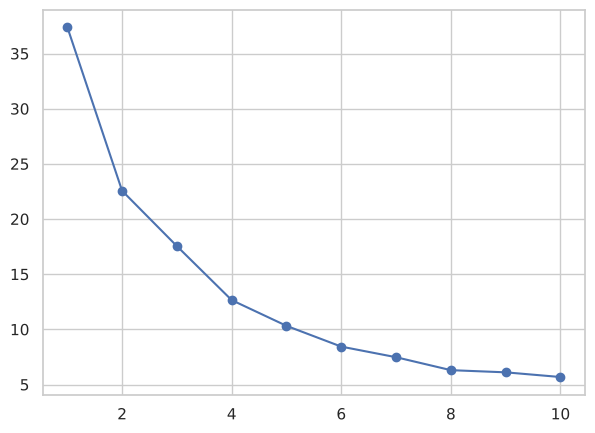

In [84]:
plt.figure(figsize=(7,5))
plt.plot(k_values, inercia, marker='o')

Text(0, 0.5, 'Inercia (SSE)')

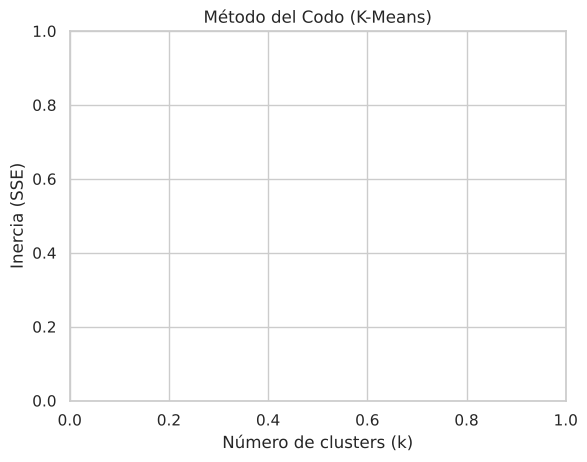

In [85]:
plt.title('Método del Codo (K-Means)')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia (SSE)')

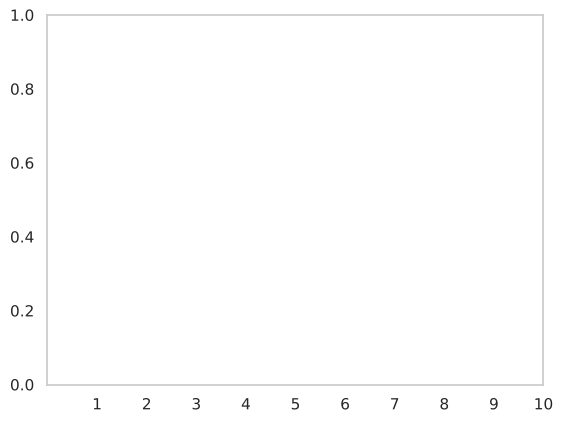

In [86]:
plt.xticks(k_values)
plt.grid()

In [87]:
plt.show()

In [88]:
from sklearn.cluster import KMeans

In [89]:
k = 5

In [90]:
resultados = []

In [91]:
for seed in range(10000):

    kmeans = KMeans(n_clusters=k,init='random',n_init=1,random_state=seed)

    kmeans.fit(X_norm)

    # Guardamos la inercia
    resultados.append({
        'seed': seed,
        'inercia': kmeans.inertia_
    })

In [92]:
# Convertir a DataFrame
resultados_df = pd.DataFrame(resultados)

In [93]:
# Mostrar resultados ordenados
resultados_df.sort_values(by='inercia')

,seed,inercia
3491,3491,10.303965
5531,5531,10.303965
6031,6031,10.303965
6037,6037,10.303965
9620,9620,10.303965
...,...,...
4987,4987,14.810718
9188,9188,14.835511
6564,6564,14.873205
5142,5142,14.890219


Para evaluar la calidad del modelo de clustering, se seleccionan métricas que consideran tanto la cohesión interna de los clusters como la separación entre ellos.

A diferencia de la inercia, que solo mide la compactación, estas métricas permiten evaluar la estructura global del agrupamiento.

El uso combinado de Silhouette, Davies-Bouldin y Calinski-Harabasz proporciona una evaluación más completa y robusta del modelo.

In [94]:
k = 5
seed = 3637

In [95]:
from sklearn.cluster import KMeans

In [96]:
kmeans = KMeans(n_clusters=k,init='random', n_init=1, random_state=seed)

In [97]:
kmeans.fit(X_norm)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",3637
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 3)","[[0.5 ,

In [98]:
labels = kmeans.labels_

In [99]:
df["Cluster"] = kmeans.labels_

## ¿Cómo sabemos si los grupos quedaron bien?

Después de agrupar a los clientes, podemos usar tres medidas para evaluar el resultado: **Silhouette**, **Davies-Bouldin** y **Calinski-Harabasz**.

Imagina que cada grupo es un equipo en el patio de una escuela. Nos interesa que los integrantes de un mismo equipo estén cerca entre sí y que los equipos estén separados unos de otros.

### 1. Silhouette Score: ¿estoy en el equipo correcto?

Compara qué tan cerca está cada dato de los integrantes de su grupo y de los integrantes del grupo vecino más cercano.

Su resultado va de **−1 a 1**:

- **Cerca de 1:** el dato encaja bien en su grupo y está separado de otros grupos.
- **Cerca de 0:** el dato está en la frontera entre dos grupos.
- **Menor que 0:** el dato está, en promedio, más cerca de otro grupo que del suyo.

La función `silhouette_score` devuelve el promedio de estos resultados para todos los datos.

**En general, cuanto más alto, mejor.**

### 2. Davies-Bouldin Score: ¿los equipos se confunden entre sí?

Evalúa qué tan dispersos están los datos dentro de cada grupo y qué tan separados están los centros de los grupos.

En la analogía del patio, un buen resultado ocurre cuando los integrantes están cerca de su equipo y lejos de los demás equipos.

Su resultado es **0 o mayor**, sin un máximo fijo.

**En general, cuanto más bajo, mejor:** indica grupos más compactos y separados.

### 3. Calinski-Harabasz Score: ¿hay más separación entre equipos que dentro de ellos?

Compara la separación entre los grupos con la dispersión de los datos dentro de cada grupo, tomando en cuenta la cantidad de datos y grupos.

Piensa en equipos cuyos integrantes están juntos, pero cada equipo ocupa una zona distinta del patio. Esa organización suele obtener un puntaje alto.

**En general, cuanto más alto, mejor.** No tiene un límite superior fijo ni un número universal que indique que el resultado es bueno.

| Medida | ¿Qué buscamos? | Mejor resultado |
|---|---|---|
| **Silhouette** | Que cada dato encaje en su grupo y esté lejos de otros. | Más cerca de **1**. |
| **Davies-Bouldin** | Grupos compactos cuyos centros estén separados. | Más cerca de **0**. |
| **Calinski-Harabasz** | Mucha separación entre grupos y poca dispersión dentro de ellos. | Un valor **más alto**. |

### ¿Cómo debemos interpretarlas?

Estas medidas se deben comparar usando **los mismos datos, variables y escalado**. Sus valores no se comparan directamente entre sí: un Silhouette de 0.6 no se compara con un Calinski-Harabasz de 200.

Para calcularlas, necesitamos al menos **2 grupos** y menos grupos que datos.

**Ninguna medida garantiza por sí sola que los grupos sean útiles.** También debemos revisar las gráficas y comprobar si los perfiles de clientes tienen sentido para el proyecto.

In [100]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [101]:
sse_kmeans = kmeans.inertia_

In [102]:
silhouette_kmeans = silhouette_score(X_norm, labels)
db_kmeans = davies_bouldin_score(X_norm, labels)
ch_kmeans = calinski_harabasz_score(X_norm, labels)

In [103]:
resultados = pd.DataFrame({
    "Algoritmo": ["KMeans"],
    "Seed": [seed],
    "Clusters (k)": [k],
    "SSE": [sse_kmeans],
    "Silhouette": [silhouette_kmeans],
    "Davies-Bouldin": [db_kmeans],
    "Calinski-Harabasz": [ch_kmeans]
})
resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,3637,5,10.303965,0.406117,0.879548,128.203462


In [104]:
cluster_profile_kmeans = (
    df.groupby("Cluster")[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
    .mean()
)

In [105]:
cluster_profile_kmeans

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
Cluster,,,
0,44.000000,90.133333,17.933333
1,25.521739,26.304348,78.565217
2,55.551724,48.482759,41.775862
3,32.875000,86.100000,81.525000
4,27.061224,51.979592,41.040816


In [106]:
print(cluster_profile_kmeans.to_string())

              Edad  Ingreso_Anual_k$  Puntaje_Gasto
Cluster                                            
0        44.000000         90.133333      17.933333
1        25.521739         26.304348      78.565217
2        55.551724         48.482759      41.775862
3        32.875000         86.100000      81.525000
4        27.061224         51.979592      41.040816


In [107]:
import plotly.express as px

In [108]:
# Convertir el número de cluster a categoría para usar colores distintos
datos_grafica = df.copy()
datos_grafica["Cluster"] = datos_grafica["Cluster"].astype(str)

In [109]:
fig = px.scatter_3d(
    datos_grafica,
    x="Edad",
    y="Ingreso_Anual_k$",
    z="Puntaje_Gasto",
    color="Cluster",
    title="Clusters de clientes con K-Means",
    labels={
        "Edad": "Edad (años)",
        "Ingreso_Anual_k$": "Ingreso anual (miles de dólares)",
        "Puntaje_Gasto": "Puntaje de gasto",
        "Cluster": "Cluster"
    },
    color_discrete_sequence=px.colors.qualitative.Safe,
    opacity=0.8
)

In [110]:
fig.update_traces(marker=dict(size=5))

In [111]:
fig.update_layout(
    height=700,
    margin=dict(l=0, r=0, b=0, t=50)
)

In [112]:
fig.show()

## ¿Qué es K-Means++ y en qué se diferencia de K-Means?

K-Means funciona en ciclos:

1. Coloca **K centros** (centroides) en algún lugar.
2. Cada cliente se une al centro más cercano.
3. Cada centro se mueve al promedio de sus clientes.
4. Se repiten los pasos 2 y 3 hasta que los centros casi no se muevan.

El problema está en el **paso 1**: ¿dónde ponemos los centros al inicio?

Imagina que en el patio hay que elegir 5 capitanes para formar equipos.

- **Inicio aleatorio (`init='random'`):** se eligen 5 alumnos al azar. Puede pasar que 3 capitanes estén juntos en la misma esquina y una zona del patio se quede sin capitán. Los equipos quedan mal repartidos.
- **K-Means++ (`init='k-means++'`):** el primer capitán se elige al azar, pero los siguientes se eligen **preferentemente lejos de los capitanes que ya existen**. Así quedan repartidos por todo el patio desde el principio.

Más técnicamente: cada nuevo centro se elige con una probabilidad proporcional al **cuadrado de la distancia** al centro más cercano ya elegido. Un punto lejano tiene más posibilidades de ser elegido, pero no es seguro: sigue habiendo azar.

Después de elegir los centros iniciales, K-Means++ sigue exactamente los mismos pasos que K-Means. **Solo cambia el inicio**, pero eso suele dar mejores grupos y en menos ciclos.

### Hiperparámetros principales

| Hiperparámetro | ¿Qué controla? | Analogía |
|---|---|---|
| `n_clusters` | Cuántos grupos (K) formar. | Cuántos equipos habrá en el patio. |
| `init` | Cómo se eligen los centros iniciales: `'k-means++'` o `'random'`. | Cómo se eligen los capitanes. |
| `n_init` | Cuántas veces se repite todo el proceso con distintos inicios; se queda con el de menor inercia. | Repetir la elección de capitanes varias veces y quedarse con la mejor organización. |
| `max_iter` | Máximo de ciclos (pasos 2 y 3) en cada intento. | Cuántas veces se permite reacomodar a los alumnos. |
| `tol` | Qué tan poco deben moverse los centros para considerar que ya terminó. | Si los capitanes ya casi no se mueven, se termina. |
| `random_state` | Fija el azar para obtener siempre el mismo resultado. | Usar siempre la misma "moneda" para sortear. |

### ¿Con qué hay que tener cuidado?

- **Hay que elegir K antes.** K-Means++ no decide cuántos grupos existen; para eso usamos el método del codo y las métricas de evaluación.
- **Escalar las variables.** Si una variable tiene números más grandes (por ejemplo, ingreso), dominaría las distancias. Por eso usamos `MinMaxScaler`.
- **Es sensible a valores atípicos.** El centro es un promedio, y un cliente muy extremo puede jalarlo hacia él, igual que una calificación de 0 baja mucho un promedio.
- **Supone grupos "redondos" y de tamaño parecido.** Si los grupos reales tienen formas alargadas o curvas, K-Means puede separarlos mal.
- **No garantiza la mejor solución posible.** Mejora mucho el inicio, pero puede quedarse en una solución "buena" y no en la "mejor". Por eso se usa `n_init` mayor que 1.
- **Un `n_init` muy grande cuesta tiempo.** Con K-Means++ normalmente bastan entre 10 y 50 repeticiones; valores como 10,000 hacen el cálculo mucho más lento y casi nunca mejoran el resultado.
- **Los números de los clusters no significan nada.** El "Cluster 0" de K-Means y el "Cluster 0" de K-Means++ no son necesariamente el mismo grupo. Para compararlos hay que revisar sus perfiles (promedios de edad, ingreso y gasto), no su número.

In [113]:
kmeans_pp = KMeans(n_clusters=k,init='k-means++', n_init=10000, random_state=seed)

In [114]:
kmeans_pp.fit(X_norm)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10000
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",3637
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 3)","

In [115]:
labels_pp = kmeans_pp.labels_

In [116]:
silhouette_pp = silhouette_score(X_norm, labels_pp)
db_pp = davies_bouldin_score(X_norm, labels_pp)
ch_pp = calinski_harabasz_score(X_norm, labels_pp)

In [117]:
nueva_fila = pd.DataFrame({
    "Algoritmo": ["KMeans++"],
    "Seed": [seed],
    "Clusters (k)": [k],
    "Silhouette": [silhouette_pp],
    "Davies-Bouldin": [db_pp],
    "Calinski-Harabasz": [ch_pp]
})

In [118]:
resultados = pd.concat([resultados, nueva_fila], ignore_index=True)

In [119]:
resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,3637,5,10.303965,0.406117,0.879548,128.203462
1,KMeans++,3637,5,NaN,0.406117,0.879548,128.203462


In [120]:
df["Cluster_KPP"] = labels_pp

In [121]:
cluster_profile_kpp = (
    df.groupby("Cluster_KPP")[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
    .mean()
    .round(2)
)

In [122]:
cluster_profile_kpp

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
Cluster_KPP,,,
0,25.52,26.30,78.57
1,44.00,90.13,17.93
2,55.55,48.48,41.78
3,32.88,86.10,81.53
4,27.06,51.98,41.04


In [123]:
# Convertir el número de cluster a categoría para usar colores distintos
datos_grafica = df.copy()
datos_grafica["Cluster_KPP"] = datos_grafica["Cluster_KPP"].astype(str)

In [124]:
fig = px.scatter_3d(
    datos_grafica,
    x="Edad",
    y="Ingreso_Anual_k$",
    z="Puntaje_Gasto",
    color="Cluster_KPP",
    title="Clusters de clientes con K-Means++",
    labels={
        "Edad": "Edad (años)",
        "Ingreso_Anual_k$": "Ingreso anual (miles de dólares)",
        "Puntaje_Gasto": "Puntaje de gasto",
        "Cluster": "Cluster"
    },
    color_discrete_sequence=px.colors.qualitative.Safe,
    opacity=0.8
)

In [125]:
fig.update_traces(marker=dict(size=5))

In [126]:
fig.update_layout(
    height=700,
    margin=dict(l=0, r=0, b=0, t=50)
)

In [127]:
fig.show()

## ¿Qué es el Clustering Aglomerativo?

A diferencia de K-Means, aquí **no se eligen centros al inicio**. Los grupos se forman de abajo hacia arriba, uniendo poco a poco a los más parecidos.

### ¿Cómo funciona?

1. Al principio, **cada cliente es su propio grupo**.
2. Se buscan los dos grupos más cercanos y se unen.
3. Se repite el paso 2 hasta que solo quedan **K grupos** (o uno solo, si dejamos que siga).

Todo este proceso se puede dibujar como un **árbol genealógico** llamado **dendrograma**: abajo están los clientes individuales y, al subir, se ve en qué momento se fueron uniendo los grupos.

### ¿Cómo se mide la distancia entre dos grupos? (`linkage`)
Hay varias formas:

| `linkage` | ¿Cómo mide la distancia entre grupos? | En nuestro problema |
|---|---|---|
| `'single'` | Distancia entre los **dos clientes más cercanos** de cada grupo. | Un grupo de jóvenes con gasto alto y otro de adultos con gasto medio se consideran cercanos si basta con que **un** cliente de cada grupo se parezca. |
| `'complete'` | Distancia entre los **dos clientes más diferentes** de cada grupo. | Esos dos grupos solo se unen si incluso sus clientes más distintos (por ejemplo, el más joven y el mayor) se parecen. |
| `'average'` | **Promedio** de las distancias entre todos los pares de clientes. | Se compara a cada cliente de un grupo con cada cliente del otro y se promedia. Es un punto intermedio. |
| `'ward'` | Une los grupos que **menos aumenten la dispersión** dentro del nuevo grupo. | Se juntan los segmentos que, al unirse, sigan teniendo un perfil claro (edad, ingreso y gasto parecidos), útil para diseñar una campaña. |
### Hiperparámetros principales

| Hiperparámetro | ¿Qué controla? | ¿Qué podemos cambiar? |
|---|---|---|
| `n_clusters` | Cuántos grupos queremos al final. | Probar otros valores (3, 4, 6...) y comparar las métricas. Usamos 5 para comparar contra K-Means, pero menos segmentos implican menos campañas y más fáciles de manejar. |
| `linkage` | Cómo se mide la distancia entre grupos. | `'ward'`, `'complete'`, `'average'` o `'single'`. Conviene probar varios y agregarlos a la tabla de resultados; `'ward'` suele dar los segmentos más compactos. |
| `metric` | Cómo se mide la distancia entre dos clientes. | `'euclidean'` (por defecto), `'manhattan'` o `'cosine'`. Con `'manhattan'`, una diferencia grande en una sola variable (por ejemplo, ingreso) pesa menos que con la euclidiana. Si usamos `'ward'`, solo se permite `'euclidean'`. |
| `distance_threshold` | Deja de unir grupos cuando la distancia entre ellos supera este valor. | Poner `n_clusters=None` y un valor como `distance_threshold=0.5`: un valor bajo da muchos segmentos pequeños y uno alto da pocos segmentos grandes. Así los datos sugieren cuántos segmentos hay. |
### ¿Con qué hay que tener cuidado?

- **No usa azar.** Con los mismos datos siempre da los mismos segmentos, por eso en la tabla de resultados la semilla aparece como "N/A". Esto es una ventaja: el área de marketing obtendrá siempre la misma segmentación.
- **Las uniones no se deshacen.** Si un cliente se une al principio a un segmento que no le corresponde, ahí se queda. En K-Means, en cambio, un cliente puede cambiar de segmento en cada ciclo.
- **El `linkage` cambia mucho los segmentos.** Con `'single'` se pueden formar "cadenas": clientes de ingreso bajo se van conectando con los de ingreso medio y estos con los de ingreso alto, hasta formar un segmento enorme que mezcla perfiles muy distintos. `'ward'` suele dar segmentos más compactos, parecidos a los de K-Means.
- **`'ward'` solo funciona con distancia euclidiana.**
- **Hay que escalar las variables.** Edad, ingreso y puntaje de gasto tienen rangos distintos; sin `MinMaxScaler`, la variable con números más grandes pesaría más al decidir qué clientes se parecen.
- **Es lento con muchos datos.** Compara a todos los clientes contra todos. Con los 200 clientes de este dataset no hay problema, pero con la base completa de un e-commerce grande sería muy pesado.
- **No clasifica clientes nuevos.** No tiene `predict()`: si se registra un cliente nuevo, no se le puede asignar directamente a un segmento; habría que volver a correr el proceso o usar otro modelo, como K-Means.

In [128]:
k = 5
linkage = "average"   # se puede cambiar: ward, complete, average, single

In [129]:
from sklearn.cluster import AgglomerativeClustering

In [130]:
agglo = AgglomerativeClustering(n_clusters=k,linkage=linkage)

In [131]:
labels_agglo = agglo.fit_predict(X_norm)

In [132]:
silhouette_agglo = silhouette_score(X_norm, labels_agglo)
db_agglo = davies_bouldin_score(X_norm, labels_agglo)
ch_agglo = calinski_harabasz_score(X_norm, labels_agglo)

In [133]:
nueva_fila = pd.DataFrame({
    "Algoritmo": [f"Agglomerative ({linkage})"],
    "Seed": ["N/A"],
    "Clusters (k)": [k],
    "Silhouette": [silhouette_agglo],
    "Davies-Bouldin": [db_agglo],
    "Calinski-Harabasz": [ch_agglo]
})

In [134]:
resultados = pd.concat([resultados, nueva_fila], ignore_index=True)

In [135]:
resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,3637,5,10.303965,0.406117,0.879548,128.203462
1,KMeans++,3637,5,NaN,0.406117,0.879548,128.203462
2,Agglomerative (average),N/A,5,NaN,0.398288,0.978435,115.403889


In [136]:
df["Cluster_Agglo"] = labels_agglo

In [137]:
cluster_profile_agglo = (
    df.groupby("Cluster_Agglo")[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
    .mean()
    .round(2)
)

In [138]:
cluster_profile_agglo

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
Cluster_Agglo,,,
0,41.69,88.23,17.29
1,43.90,24.45,19.10
2,24.65,42.94,62.08
3,53.26,54.20,48.56
4,32.69,86.54,82.13


In [139]:
# Convertir el número de cluster a categoría para usar colores distintos
datos_grafica = df.copy()
datos_grafica["Cluster_Agglo"] = datos_grafica["Cluster_Agglo"].astype(str)

In [140]:
fig = px.scatter_3d(
    datos_grafica,
    x="Edad",
    y="Ingreso_Anual_k$",
    z="Puntaje_Gasto",
    color="Cluster_Agglo",
    title="Cluster_Agglo",
    labels={
        "Edad": "Edad (años)",
        "Ingreso_Anual_k$": "Ingreso anual (miles de dólares)",
        "Puntaje_Gasto": "Puntaje de gasto",
        "Cluster": "Cluster"
    },
    color_discrete_sequence=px.colors.qualitative.Safe,
    opacity=0.8
)

In [141]:
fig.update_traces(marker=dict(size=5))

In [142]:
fig.update_layout(
    height=700,
    margin=dict(l=0, r=0, b=0, t=50)
)

In [143]:
fig.show()

## ¿Qué es Bisecting K-Means (clustering divisivo)?

Es lo **contrario del aglomerativo**: en lugar de empezar con cada cliente por separado e ir uniendo, empieza con **todos los clientes en un solo grupo** y lo va partiendo.

### ¿Cómo funciona?

1. Todos los clientes empiezan en un mismo segmento.
2. Se aplica K-Means con K = 2 para partir ese segmento en dos.
3. Se elige el segmento más "revuelto" (el de mayor inercia) y se vuelve a partir en dos.
4. Se repite hasta tener **K segmentos**.

### Hiperparámetros principales

| Hiperparámetro | ¿Qué controla? | ¿Qué podemos cambiar? |
|---|---|---|
| `n_clusters` | Cuántos segmentos queremos al final. | Probar otros valores (3, 4, 6...) y comparar las métricas. Usamos 5 para comparar contra los demás modelos. |
| `bisecting_strategy` | Qué segmento se parte en cada paso. | `'biggest_inertia'` (por defecto) parte el segmento más disperso, con perfiles más mezclados. `'largest_cluster'` parte el que tiene más clientes, lo que da segmentos de tamaño más parecido. |
| `init` | Cómo se eligen los centros iniciales en cada división. | Por defecto es `'random'`. Podemos cambiarlo a `'k-means++'` para que cada división empiece mejor. |
| `n_init` | Cuántas veces se intenta cada división con distintos inicios. | Por defecto es 1. Subirlo a 5 o 10 hace que cada corte sea más confiable, a cambio de más tiempo. |
| `random_state` | Fija el azar. | Cambiar la semilla y revisar si los segmentos cambian mucho; si cambian, el resultado es poco estable. |

### ¿Con qué hay que tener cuidado?

- **Las divisiones no se deshacen.** Si en el primer corte dos clientes parecidos quedan en lados distintos, ya no se vuelven a juntar.
- **Sí usa azar.** Cada división es un K-Means, por eso necesita `random_state` para dar siempre el mismo resultado.
- **Hereda las limitaciones de K-Means:** supone segmentos "redondos", el promedio se ve afectado por clientes extremos y hay que escalar las variables.
- **El orden de los cortes importa.** Con `'biggest_inertia'` puede quedar un segmento muy pequeño junto a otros muy grandes, lo que importa si cada segmento será una campaña.
- **Sí clasifica clientes nuevos.** A diferencia del aglomerativo, tiene `predict()`: un cliente nuevo se puede asignar directamente al segmento más cercano.

In [144]:
from sklearn.cluster import BisectingKMeans

In [145]:
k = 5
bisect_kmeans = BisectingKMeans(
    n_clusters=k,
    random_state=seed
)

In [146]:
labels_div = bisect_kmeans.fit_predict(X_norm)

In [147]:
silhouette_div = silhouette_score(X_norm, labels_div)
db_div = davies_bouldin_score(X_norm, labels_div)
ch_div = calinski_harabasz_score(X_norm, labels_div)

In [148]:
nueva_fila = pd.DataFrame({
    "Algoritmo": ["Divisivo (Bisecting K-Means)"],
    "Seed": [seed],
    "Clusters (k)": [k],
    "Silhouette": [silhouette_div],
    "Davies-Bouldin": [db_div],
    "Calinski-Harabasz": [ch_div]
})

In [149]:
resultados = pd.concat([resultados, nueva_fila], ignore_index=True)

In [150]:
resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,3637,5,10.303965,0.406117,0.879548,128.203462
1,KMeans++,3637,5,NaN,0.406117,0.879548,128.203462
2,Agglomerative (average),N/A,5,NaN,0.398288,0.978435,115.403889
3,Divisivo (Bisecting K-Means),3637,5,NaN,0.398145,0.970277,121.102627


In [151]:
df["Cluster_Div"] = labels_div

In [152]:
cluster_profile_div = (
    df.groupby("Cluster_Div")[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
    .mean()
    .round(2)
)

In [153]:
cluster_profile_div

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
Cluster_Div,,,
0,55.64,54.38,48.85
1,48.20,29.50,18.60
2,40.00,85.69,17.97
3,25.19,42.75,60.77
4,32.88,86.10,81.53


In [154]:
# Convertir el número de cluster a categoría para usar colores distintos
datos_grafica = df.copy()
datos_grafica["Cluster_Div"] = datos_grafica["Cluster_Div"].astype(str)

In [155]:
fig = px.scatter_3d(
    datos_grafica,
    x="Edad",
    y="Ingreso_Anual_k$",
    z="Puntaje_Gasto",
    color="Cluster_Div",
    title="Cluster_Div",
    labels={
        "Edad": "Edad (años)",
        "Ingreso_Anual_k$": "Ingreso anual (miles de dólares)",
        "Puntaje_Gasto": "Puntaje de gasto",
        "Cluster": "Cluster"
    },
    color_discrete_sequence=px.colors.qualitative.Safe,
    opacity=0.8
)

In [156]:
fig.update_traces(marker=dict(size=5))

In [157]:
fig.update_layout(
    height=700,
    margin=dict(l=0, r=0, b=0, t=50)
)

In [158]:
fig.show()

## ¿Qué es DBSCAN?

DBSCAN forma segmentos buscando **zonas donde hay muchos clientes juntos**. A diferencia de K-Means, **no necesitamos decirle cuántos segmentos queremos**: los encuentra solo.

### ¿Cómo funciona?

Para cada cliente, DBSCAN revisa cuántos clientes tiene cerca (dentro de una distancia llamada `eps`):

- **Cliente núcleo:** tiene al menos `min_samples` clientes cerca, contándose a sí mismo. Está en una zona "llena".
- **Cliente frontera:** no tiene suficientes vecinos, pero está cerca de un cliente núcleo. Pertenece al segmento, en la orilla.
- **Ruido:** no está cerca de ningún núcleo. Queda **sin segmento** y recibe la etiqueta **-1**.

Los clientes núcleo que están cerca entre sí se van encadenando y forman un mismo segmento.

### En nuestro problema

En la gráfica 3D de edad, ingreso y puntaje de gasto, hay zonas donde se amontonan muchos clientes, por ejemplo jóvenes con ingreso medio y gasto alto. DBSCAN convierte cada una de esas zonas en un segmento.

Los clientes que quedan aislados, por ejemplo alguien con un ingreso muy alto y un gasto muy bajo que no se parece a nadie, se marcan como **ruido**. Para marketing esto es útil: son clientes atípicos que no conviene meter a la fuerza en una campaña pensada para otro perfil.

### ¿Cómo elegimos `eps`? La gráfica k-distance

1. Para cada cliente, medimos la distancia a su vecino número `min_samples` (contándose a sí mismo).
2. Ordenamos esas distancias de menor a mayor y las graficamos.
3. La curva sube despacio y luego se dispara. El punto donde **empieza a subir rápido** (el codo) es un buen valor para `eps`.

Los clientes a la izquierda del codo están en zonas llenas; los de la derecha están aislados y probablemente serán ruido.

### Hiperparámetros principales

| Hiperparámetro | ¿Qué controla? | ¿Qué podemos cambiar? |
|---|---|---|
| `eps` | Qué tan cerca debe estar un cliente para contar como vecino. | Tomar el valor del codo de la gráfica k-distance y probar valores cercanos (0.1, 0.15, 0.2...). Un `eps` muy pequeño deja a casi todos como ruido; uno muy grande junta a todos en un solo segmento. |
| `min_samples` | Cuántos vecinos se necesitan para ser cliente núcleo. | Una regla común es usar el doble del número de variables (aquí 3 variables → 6). Valores bajos crean muchos segmentos pequeños; valores altos exigen zonas más llenas y generan más ruido. |
| `metric` | Cómo se mide la distancia entre dos clientes. | `'euclidean'` (por defecto) o `'manhattan'`. Si se cambia, hay que volver a hacer la gráfica k-distance con la misma métrica. |

### ¿Con qué hay que tener cuidado?

- **`eps` y `min_samples` van juntos.** La gráfica k-distance debe hacerse con el **mismo** `min_samples` que usaremos en DBSCAN; si cambiamos uno, el `eps` adecuado también cambia.
- **Escalar es obligatorio.** `eps` es una distancia; con `MinMaxScaler` las variables van de 0 a 1, así que `eps` se interpreta en esa escala. Sin escalar, el ingreso dominaría la distancia.
- **Un solo `eps` para todos los segmentos.** Si hay un segmento muy apretado (por ejemplo, jóvenes de gasto alto) y otro más disperso (adultos de ingreso medio), un mismo `eps` no sirve bien para ambos.
- **El ruido no es un segmento.** La etiqueta -1 no debe tratarse como un cluster más ni recibir una campaña propia. Al calcular Silhouette y las demás métricas, conviene excluir el ruido o mencionarlo aparte.
- **Con pocos datos es delicado.** Con 200 clientes en 3 dimensiones hay pocas zonas realmente densas, así que es fácil terminar con un solo segmento enorme o con mucho ruido.
- **No clasifica clientes nuevos.** Igual que el aglomerativo, no tiene `predict()`.

In [159]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

In [160]:
min_samples = 5

In [161]:
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_norm)

In [162]:
distances, indices = neighbors_fit.kneighbors(X_norm)

In [163]:
distances = np.sort(distances[:, -1])

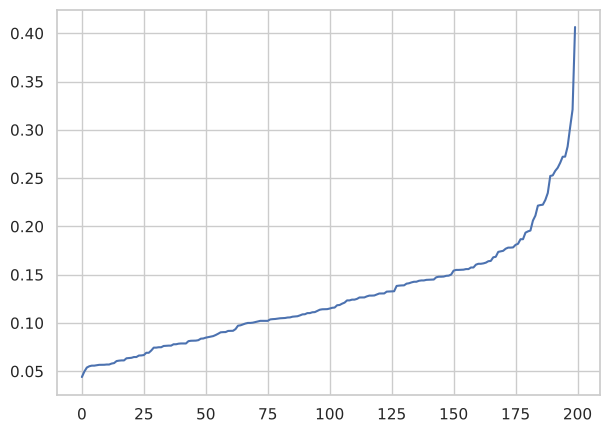

In [164]:
plt.figure(figsize=(7,5))
plt.plot(distances)

Text(0, 0.5, 'Distancia')

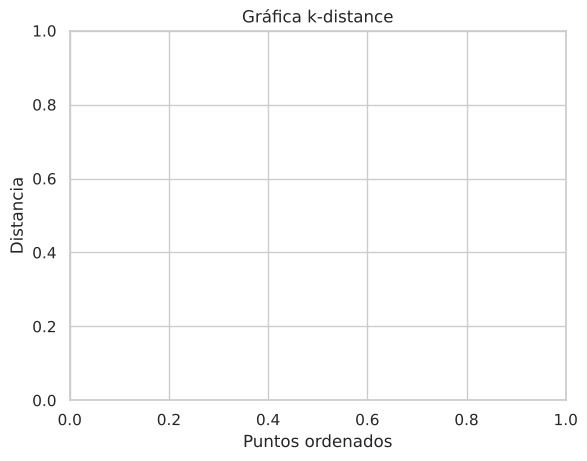

In [165]:
plt.title('Gráfica k-distance')
plt.xlabel('Puntos ordenados')
plt.ylabel('Distancia')

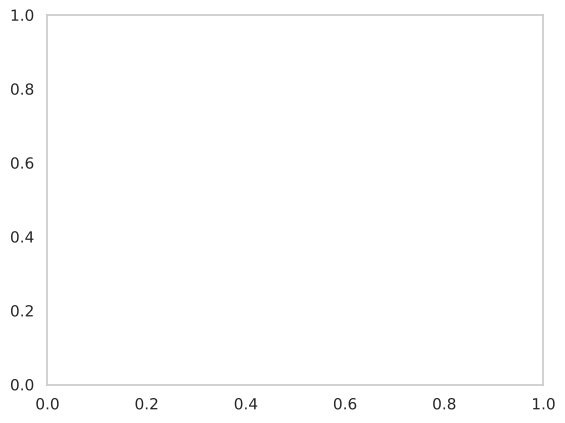

In [166]:
plt.grid()
plt.show()

In [167]:
from sklearn.cluster import DBSCAN

In [168]:
# Búsqueda de eps y min_samples por debajo del codo de la gráfica k-distance
pruebas = []

In [169]:
for ms in [4, 5, 6, 8]:
    for e in [0.08, 0.10, 0.12, 0.14, 0.16]:
        etiquetas = DBSCAN(eps=e, min_samples=ms).fit_predict(X_norm)

        n_clusters = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
        n_ruido = (etiquetas == -1).sum()

        # Silhouette sin contar el ruido (requiere al menos 2 clusters)
        mascara = etiquetas != -1
        if n_clusters >= 2:
            sil = silhouette_score(X_norm[mascara], etiquetas[mascara])
        else:
            sil = np.nan

        pruebas.append({
            "min_samples": ms,
            "eps": e,
            "Clusters": n_clusters,
            "Ruido": n_ruido,
            "% Ruido": round(100 * n_ruido / len(etiquetas), 1),
            "Silhouette (sin ruido)": sil
        })

In [170]:
pruebas_df = pd.DataFrame(pruebas)
pruebas_df

,min_samples,eps,Clusters,Ruido,% Ruido,Silhouette (sin ruido)
0,4,0.08,7,111,55.5,0.568016
1,4,0.10,6,77,38.5,0.552639
2,4,0.12,9,36,18.0,0.430290
3,4,0.14,5,23,11.5,0.210685
4,4,0.16,3,11,5.5,0.192486
5,5,0.08,8,122,61.0,0.579155
6,5,0.10,7,98,49.0,0.478531
7,5,0.12,5,60,30.0,0.497101
8,5,0.14,5,38,19.0,0.158976
9,5,0.16,2,17,8.5,0.255494


## ¿Qué es Mean Shift?

Mean Shift busca los **puntos donde más clientes se amontonan** y forma un segmento alrededor de cada uno. Igual que DBSCAN, **no necesitamos decirle cuántos segmentos queremos**: los encuentra solo.

### ¿Cómo funciona?

1. Alrededor de cada cliente se dibuja una "burbuja" de cierto tamaño, llamado `bandwidth`.
2. Se calcula el promedio de los clientes que quedan dentro de la burbuja y la burbuja **se mueve hacia ese promedio**.
3. Se repite: la burbuja se va desplazando hacia donde hay más clientes, hasta que deja de moverse.
4. Las burbujas que terminan en el mismo lugar forman un mismo segmento.

### Hiperparámetros principales

| Hiperparámetro | ¿Qué controla? | ¿Qué podemos cambiar? |
|---|---|---|
| `bandwidth` | El tamaño de la burbuja. Es el parámetro más importante. | Una burbuja pequeña encuentra muchas cimas pequeñas (muchos segmentos); una grande junta todo en pocas cimas (pocos segmentos). Podemos fijarlo a mano o estimarlo con `estimate_bandwidth`. |
| `quantile` (en `estimate_bandwidth`) | Qué proporción de clientes se usa como vecinos para estimar el `bandwidth`. | Valores bajos (0.1) dan un `bandwidth` pequeño y más segmentos; valores altos (0.3) dan menos segmentos. Usamos 0.12; conviene probar 0.1, 0.15 y 0.2 y comparar. |
| `bin_seeding` | Si las burbujas empiezan en cada cliente o en una cuadrícula. | `True` acelera el cálculo usando una cuadrícula; `False` empieza en cada cliente. Con 200 clientes ambas opciones son rápidas. |
| `cluster_all` | Qué hacer con los clientes que no llegan a ninguna cima. | `True` (por defecto) los asigna a la cima más cercana; `False` los marca como ruido (-1), igual que DBSCAN. |

### ¿Con qué hay que tener cuidado?

- **El `bandwidth` lo decide casi todo.** Un cambio pequeño puede pasar de 3 a 8 segmentos. Hay que probar varios valores y revisar si los segmentos tienen sentido para marketing.
- **Escalar es obligatorio.** La burbuja es una distancia; sin `MinMaxScaler`, la variable con números más grandes determinaría su forma.
- **Un solo tamaño de burbuja para todos.** Si un segmento es muy compacto y otro muy disperso, un mismo `bandwidth` no sirve bien para ambos.
- **Puede crear segmentos muy pequeños.** Una cima con 2 o 3 clientes es un "segmento" para el modelo, pero no justifica una campaña. Hay que revisar cuántos clientes hay en cada uno.
- **No usa azar** (con un `bandwidth` fijo da siempre lo mismo), por eso la semilla aparece como "N/A".
- **Es lento con muchos datos.** Con 200 clientes no hay problema, pero con una base grande sí.
- **Sí clasifica clientes nuevos.** Tiene `predict()`: un cliente nuevo se asigna a la cima más cercana.

In [171]:
from sklearn.cluster import MeanShift, estimate_bandwidth

In [172]:
from sklearn.cluster import MeanShift, estimate_bandwidth

In [173]:
# Probar varios quantiles y ambas formas de iniciar las burbujas
pruebas_ms = []

In [174]:
for q in [0.08, 0.10, 0.12, 0.15, 0.20]:
    bw = estimate_bandwidth(X_norm, quantile=q)

    for bs in [True, False]:
        etiquetas = MeanShift(bandwidth=bw, bin_seeding=bs).fit_predict(X_norm)
        tamanos = pd.Series(etiquetas).value_counts()
        n_cl = len(tamanos)

        pruebas_ms.append({
            "quantile": q,
            "bandwidth": round(bw, 3),
            "bin_seeding": bs,
            "Clusters": n_cl,
            "Cluster más pequeño": tamanos.min(),
            "Silhouette": silhouette_score(X_norm, etiquetas) if n_cl >= 2 else np.nan
        })

In [175]:
pruebas_ms_df = pd.DataFrame(pruebas_ms)
pruebas_ms_df

,quantile,bandwidth,bin_seeding,Clusters,Cluster más pequeño,Silhouette
0,0.08,0.222,True,10,2,0.401469
1,0.08,0.222,False,13,1,0.398128
2,0.10,0.252,True,10,2,0.416699
3,0.10,0.252,False,9,3,0.407302
4,0.12,0.279,True,5,7,0.368152
5,0.12,0.279,False,5,7,0.368152
6,0.15,0.312,True,2,80,0.336565
7,0.15,0.312,False,3,35,0.364097
8,0.20,0.369,True,1,200,NaN
9,0.20,0.369,False,1,200,NaN


In [176]:
bandwidth = estimate_bandwidth(X_norm, quantile=0.12)

In [177]:
print("Bandwidth estimado:", bandwidth)
meanshift = MeanShift(
    bandwidth=bandwidth,
    bin_seeding=True
)

Bandwidth estimado: 0.2793594254829411


In [178]:
labels_ms = meanshift.fit_predict(X_norm)

In [179]:
import numpy as np

In [180]:
n_clusters_ms = len(np.unique(labels_ms))

In [181]:
print("Número de clusters:", n_clusters_ms)

Número de clusters: 5


In [182]:
silhouette_ms = silhouette_score(X_norm, labels_ms)
db_ms = davies_bouldin_score(X_norm, labels_ms)
ch_ms = calinski_harabasz_score(X_norm, labels_ms)

In [183]:
nueva_fila = pd.DataFrame({
    "Algoritmo": ["MeanShift"],
    "Seed": ["N/A"],
    "Clusters (k)": [n_clusters_ms],
    "Silhouette": [silhouette_ms],
    "Davies-Bouldin": [db_ms],
    "Calinski-Harabasz": [ch_ms]
})

In [184]:
resultados = pd.concat([resultados, nueva_fila], ignore_index=True)

In [185]:
resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,3637,5,10.303965,0.406117,0.879548,128.203462
1,KMeans++,3637,5,NaN,0.406117,0.879548,128.203462
2,Agglomerative (average),N/A,5,NaN,0.398288,0.978435,115.403889
3,Divisivo (Bisecting K-Means),3637,5,NaN,0.398145,0.970277,121.102627
4,MeanShift,N/A,5,NaN,0.368152,1.074665,101.583981


In [186]:
df["Cluster_MS"] = labels_ms

In [187]:
cluster_profile_ms = (
    df.groupby("Cluster_MS")[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
    .mean()
    .round(2)
)

In [188]:
cluster_profile_ms

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
Cluster_MS,,,
0,55.73,48.55,43.51
1,26.64,44.89,56.72
2,32.60,82.26,83.14
3,44.06,84.34,17.46
4,24.14,42.43,12.00


In [189]:
# Convertir el número de cluster a categoría para usar colores distintos
datos_grafica = df.copy()
datos_grafica["Cluster_MS"] = datos_grafica["Cluster_MS"].astype(str)

In [190]:
fig = px.scatter_3d(
    datos_grafica,
    x="Edad",
    y="Ingreso_Anual_k$",
    z="Puntaje_Gasto",
    color="Cluster_MS",
    title="Cluster_MS",
    labels={
        "Edad": "Edad (años)",
        "Ingreso_Anual_k$": "Ingreso anual (miles de dólares)",
        "Puntaje_Gasto": "Puntaje de gasto",
        "Cluster": "Cluster"
    },
    color_discrete_sequence=px.colors.qualitative.Safe,
    opacity=0.8
)

In [191]:
fig.update_traces(marker=dict(size=5))

In [192]:
fig.update_layout(
    height=700,
    margin=dict(l=0, r=0, b=0, t=50)
)

In [193]:
fig.show()

# AIC y BIC: ¿cuántos segmentos elegir en un modelo GMM?

### ¿Qué es GMM?

El modelo de mezclas gaussianas (**GMM**) supone que cada segmento de clientes tiene forma de "nube" con un centro y una forma (redonda, alargada o inclinada). A diferencia de K-Means, no asigna a cada cliente a un solo grupo de forma tajante: calcula la **probabilidad** de que pertenezca a cada segmento. Por ejemplo, una clienta podría tener 80 % de probabilidad de ser del segmento "jóvenes de gasto alto" y 20 % de "adultos de ingreso medio".

Si usamos más segmentos, el modelo se ajusta mejor a los datos. Con 200 segmentos, cada cliente tendría su propia nube y el ajuste sería perfecto, pero no serviría para nada: no podemos hacer 200 campañas.

AIC y BIC resuelven esto dando una **calificación que premia el buen ajuste y castiga la complejidad**.

Imagina que debes resumir un libro. Un resumen que copia el libro completo "explica todo", pero no es un buen resumen. Una buena calificación premia que el resumen explique la historia, pero le quita puntos por cada página de más.

### Las fórmulas

$$\text{AIC} = -2\ln(L) + 2p$$

$$\text{BIC} = -2\ln(L) + p\ln(n)$$

| Símbolo | ¿Qué es? | En nuestro problema |
|---|---|---|
| $L$ | **Verosimilitud:** qué tan probable es observar nuestros datos si el modelo fuera cierto. Más alta es mejor. | Qué tan bien las nubes del GMM describen a nuestros clientes. |
| $p$ | **Número de parámetros** del modelo: su complejidad. | Con 3 variables y covarianza `'full'`, cada segmento necesita 3 valores para su centro, 6 para su forma y 1 para su peso. Con 5 segmentos son 49 parámetros. |
| $n$ | Número de observaciones. | Los 200 clientes. |


### ¿Cómo funciona?

GMM usa un procedimiento llamado **EM (Expectation-Maximization)**, que repite dos pasos:

1. **Paso E (calcular probabilidades):** con las nubes actuales, calcula para cada cliente la probabilidad de pertenecer a cada nube.
2. **Paso M (ajustar las nubes):** mueve el centro y cambia la forma de cada nube usando esas probabilidades. Un cliente con 90 % de probabilidad "jala" mucho la nube; uno con 10 %, casi nada.
3. Repite hasta que las nubes casi no cambien.

### Tipos de forma de las nubes (`covariance_type`)

| Tipo | Forma de cada nube | En nuestro problema |
|---|---|---|
| `'spherical'` | Redonda, cada una de su tamaño. | Lo más parecido a K-Means. Pocos parámetros. |
| `'diag'` | Alargada, pero solo a lo largo de los ejes. | Un segmento puede ser muy variado en edad pero muy parecido en ingreso. |
| `'tied'` | Todas las nubes tienen la misma forma. | Todos los segmentos se "estiran" igual. |
| `'full'` | Cada nube tiene su propia forma e inclinación. | Un segmento puede tener la forma "a mayor ingreso, mayor gasto". Es la más flexible, pero usa más parámetros. |

### Hiperparámetros principales

| Hiperparámetro | ¿Qué controla? | ¿Qué podemos cambiar? |
|---|---|---|
| `n_components` | Cuántas nubes (segmentos) habrá. | Elegirlo con AIC y BIC (siguiente sección). Usamos 5 para comparar con los demás modelos. |
| `covariance_type` | La forma permitida de las nubes. | `'full'`, `'tied'`, `'diag'` o `'spherical'`. Conviene comparar el BIC de cada uno: `'full'` ajusta mejor, pero `'spherical'` o `'diag'` pueden ser suficientes con menos parámetros. |
| `n_init` | Cuántas veces se repite el proceso desde distintos puntos de inicio. | Por defecto es 1. Subirlo a 5 o 10 evita quedarse con una mala solución. |
| `init_params` | Cómo se colocan las nubes al inicio. | `'kmeans'` (por defecto) empieza desde un K-Means; también se puede usar `'k-means++'` o `'random'`. |
| `random_state` | Fija el azar. | Cambiar la semilla y revisar si los segmentos se mantienen; si cambian mucho, el resultado es poco estable. |

### ¿Con qué hay que tener cuidado?

- **Supone que los segmentos tienen forma de nube.** Si un grupo real tiene forma curva o irregular, GMM lo describirá mal.
- **Usa azar y puede quedarse en una mala solución.** Por eso conviene usar `n_init` mayor que 1 y fijar `random_state`.
- **Hay que escalar las variables.** Igual que en los otros modelos, la variable con números más grandes dominaría la forma de las nubes.
- **`'full'` necesita suficientes datos.** Con 200 clientes y 5 segmentos son 49 parámetros. Si un segmento tiene muy pocos clientes, su forma se calcula mal.
- **Las métricas usan la asignación tajante.** Silhouette, Davies-Bouldin y Calinski-Harabasz toman a cada cliente en su segmento más probable; no consideran las probabilidades.
- **Sí clasifica clientes nuevos.** Tiene `predict()` y `predict_proba()`: a un cliente nuevo se le puede dar su segmento y su probabilidad.

In [194]:
from sklearn.mixture import GaussianMixture

In [195]:
bic_scores = []
k_values = range(1, 11)

In [196]:
for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        covariance_type='full',
        random_state=seed
    )

    gmm.fit(X_norm)
    bic_scores.append(gmm.bic(X_norm))

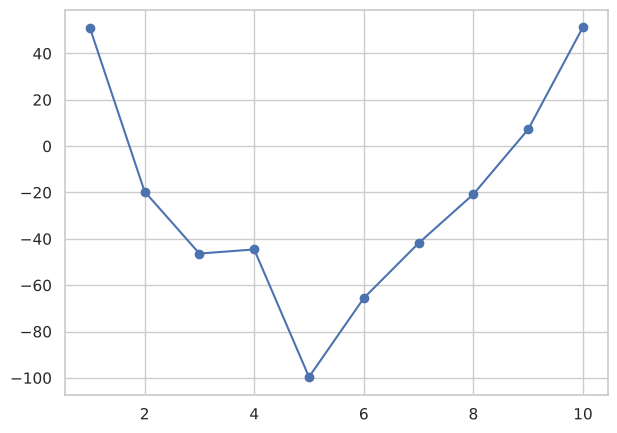

In [197]:
# Graficar
plt.figure(figsize=(7,5))
plt.plot(k_values, bic_scores, marker='o')

Text(0, 0.5, 'BIC')

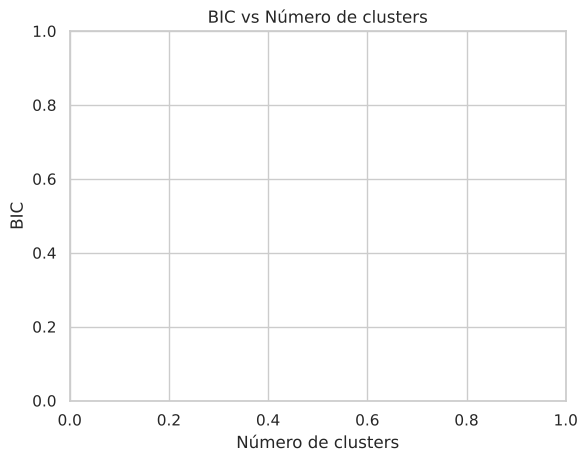

In [198]:
plt.title('BIC vs Número de clusters')
plt.xlabel('Número de clusters')
plt.ylabel('BIC')

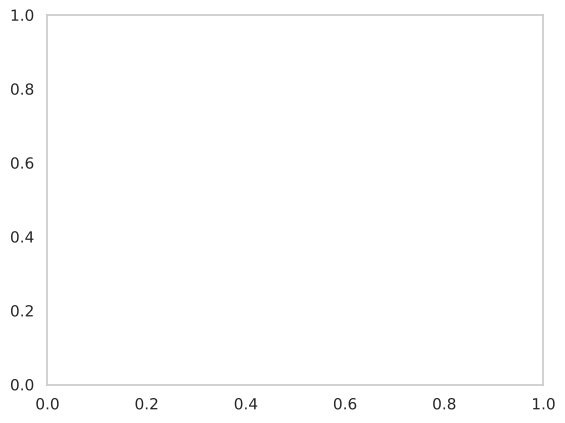

In [199]:
plt.grid()
plt.show()

In [200]:
k = 5

In [201]:
gmm = GaussianMixture(
    n_components=k,
    covariance_type='full', #'full', 'tied', 'diag', 'spherical'
    random_state=seed
)

In [202]:
gmm.fit(X_norm)

,"n_components n_components: int, default=1The number of mixture components.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",3637
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [203]:
labels_gmm = gmm.predict(X_norm)

In [204]:
probs = gmm.predict_proba(X_norm)

In [205]:
probs[:5]

array([[6.43022160e-08, 8.61167732e-05, 1.03208848e-10, 9.99913815e-01,
        3.96424578e-09],
       [1.02010087e-13, 9.99994628e-01, 5.37695056e-07, 4.83432459e-06,
        6.92582028e-23],
       [9.65791771e-18, 1.18150494e-12, 8.07952497e-19, 9.99872975e-01,
        1.27025007e-04],
       [8.27534008e-12, 9.99974982e-01, 3.77643219e-06, 2.12413331e-05,
        7.90221347e-21],
       [4.80971238e-06, 8.08094081e-04, 1.37117572e-07, 9.99186904e-01,
        5.49759091e-08]])

In [206]:
silhouette_gmm = silhouette_score(X_norm, labels_gmm)
db_gmm = davies_bouldin_score(X_norm, labels_gmm)
ch_gmm = calinski_harabasz_score(X_norm, labels_gmm)

In [207]:
nueva_fila = pd.DataFrame({
    "Algoritmo": ["GMM"],
    "Seed": [seed],
    "Clusters (k)": [k],
    "Silhouette": [silhouette_gmm],
    "Davies-Bouldin": [db_gmm],
    "Calinski-Harabasz": [ch_gmm]
})

In [208]:
resultados = pd.concat([resultados, nueva_fila], ignore_index=True)

In [209]:
resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,3637,5,10.303965,0.406117,0.879548,128.203462
1,KMeans++,3637,5,NaN,0.406117,0.879548,128.203462
2,Agglomerative (average),N/A,5,NaN,0.398288,0.978435,115.403889
3,Divisivo (Bisecting K-Means),3637,5,NaN,0.398145,0.970277,121.102627
4,MeanShift,N/A,5,NaN,0.368152,1.074665,101.583981
5,GMM,3637,5,NaN,0.394054,1.001811,115.804064


In [210]:
from sklearn.preprocessing import StandardScaler

In [211]:
scaler = StandardScaler()

In [212]:
X_std = scaler.fit_transform(
    df[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
)

In [213]:
gmm.fit(X_std)
labels_gmm = gmm.predict(X_std)
probs = gmm.predict_proba(X_std)

In [214]:
gmm.fit(X_std)
labels_gmm = gmm.predict(X_std)
probs = gmm.predict_proba(X_std)

In [215]:
from sklearn.mixture import GaussianMixture

In [216]:
k = 5

In [217]:
gmm = GaussianMixture(
    n_components=k,
    covariance_type='full',
    random_state=seed
)

In [218]:
gmm.fit(X_std)

,"n_components n_components: int, default=1The number of mixture components.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",3637
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [219]:
labels_gmm = gmm.predict(X_std)

In [220]:
probs = gmm.predict_proba(X_std)

In [221]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [222]:
sil_gmm = silhouette_score(X_std, labels_gmm)
db_gmm = davies_bouldin_score(X_std, labels_gmm)
ch_gmm = calinski_harabasz_score(X_std, labels_gmm)

In [223]:
nueva_fila = pd.DataFrame({
    "Algoritmo": ["GMM"],
    "Clusters (k)": [k],
    "Silhouette": [sil_gmm],
    "Davies-Bouldin": [db_gmm],
    "Calinski-Harabasz": [ch_gmm]
})

In [224]:
resultados = pd.concat([resultados, nueva_fila], ignore_index=True)

In [225]:
resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,3637,5,10.303965,0.406117,0.879548,128.203462
1,KMeans++,3637,5,NaN,0.406117,0.879548,128.203462
2,Agglomerative (average),N/A,5,NaN,0.398288,0.978435,115.403889
3,Divisivo (Bisecting K-Means),3637,5,NaN,0.398145,0.970277,121.102627
4,MeanShift,N/A,5,NaN,0.368152,1.074665,101.583981
5,GMM,3637,5,NaN,0.394054,1.001811,115.804064
6,GMM,NaN,5,NaN,0.406367,0.935599,116.900931


###  Silhouette Score (mas alto mejor)
Mide qué tan bien separado está cada cluster respecto a los demás.




###  Davies-Bouldin Index ( mas bajo mejor)
Evalúa la similitud entre clusters.




###  Calinski-Harabasz Index (mas alto mejor)
Mide la relación entre dispersión interna y separación entre clusters.

In [226]:
import numpy as np

In [227]:
df["Cluster_GMM"] = np.argmax(probs, axis=1)

In [228]:
df["Prob_Max"] = np.max(probs, axis=1)

In [229]:
cluster_profile_gmm = (
    df.groupby("Cluster_GMM")[["Edad", "Ingreso_Anual_k$", "Puntaje_Gasto"]]
    .mean()
    .round(2)
)

In [230]:
cluster_profile_gmm

,Edad,Ingreso_Anual_k$,Puntaje_Gasto
Cluster_GMM,,,
0,53.39,55.37,48.98
1,24.83,43.23,62.04
2,32.69,86.54,82.13
3,45.22,26.30,20.91
4,41.65,88.74,16.76


In [231]:
# Convertir el número de cluster a categoría para usar colores distintos
datos_grafica = df.copy()
datos_grafica["Cluster_GMM"] = datos_grafica["Cluster_GMM"].astype(str)

In [232]:
fig = px.scatter_3d(
    datos_grafica,
    x="Edad",
    y="Ingreso_Anual_k$",
    z="Puntaje_Gasto",
    color="Cluster_GMM",
    title="Cluster_GMM",
    labels={
        "Edad": "Edad (años)",
        "Ingreso_Anual_k$": "Ingreso anual (miles de dólares)",
        "Puntaje_Gasto": "Puntaje de gasto",
        "Cluster": "Cluster"
    },
    color_discrete_sequence=px.colors.qualitative.Safe,
    opacity=0.8
)

In [233]:
fig.update_traces(marker=dict(size=5))

In [234]:
fig.update_layout(
    height=700,
    margin=dict(l=0, r=0, b=0, t=50)
)

In [235]:
fig.show()

In [236]:
resultados

,Algoritmo,Seed,Clusters (k),SSE,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,KMeans,3637,5,10.303965,0.406117,0.879548,128.203462
1,KMeans++,3637,5,NaN,0.406117,0.879548,128.203462
2,Agglomerative (average),N/A,5,NaN,0.398288,0.978435,115.403889
3,Divisivo (Bisecting K-Means),3637,5,NaN,0.398145,0.970277,121.102627
4,MeanShift,N/A,5,NaN,0.368152,1.074665,101.583981
5,GMM,3637,5,NaN,0.394054,1.001811,115.804064
6,GMM,NaN,5,NaN,0.406367,0.935599,116.900931


In [237]:
# Creamos un dataframe con los datos de los clientes y su cluster de K-Means
df_KMEANS = df[[
    "ID_Cliente",
    "Edad",
    "Ingreso_Anual_k$",
    "Puntaje_Gasto",
    "Cluster"
]].copy()

In [238]:
# Obtenemos la lista de clusters
clusters = sorted(df_KMEANS["Cluster"].unique())

In [239]:
# Guardamos un archivo CSV por cada segmento
for cid in clusters:
    df_cluster = df_KMEANS[df_KMEANS["Cluster"] == cid]

    nombre_archivo = f"clientes_kmeans_perfil_{cid}.csv"
    df_cluster.to_csv(nombre_archivo, index=False)

    print(
        f"Archivo generado: {nombre_archivo} "
        f"— {len(df_cluster)} clientes"
    )

# Estos archivos permiten compartir la información de cada segmento
# con las personas responsables de diseñar ofertas.

Archivo generado: clientes_kmeans_perfil_0.csv — 30 clientes
Archivo generado: clientes_kmeans_perfil_1.csv — 23 clientes
Archivo generado: clientes_kmeans_perfil_2.csv — 58 clientes
Archivo generado: clientes_kmeans_perfil_3.csv — 40 clientes
Archivo generado: clientes_kmeans_perfil_4.csv — 49 clientes


In [240]:
# Tamaño de cada segmento
conteo = df["Cluster"].value_counts().sort_index()

In [241]:
# Nombres y estrategias definidos a partir de los perfiles promedio
nombres = {
    0: "Adultos de alto ingreso y bajo gasto",
    1: "Jóvenes de bajo ingreso y alto gasto",
    2: "Adultos de mayor edad con gasto moderado",
    3: "Adultos jóvenes de alto ingreso y alto gasto",
    4: "Jóvenes de ingreso y gasto moderados"
}

In [242]:
estrategias = {
    0: "Tienen capacidad de compra, pero gastan poco. Investigar por qué "
       "(encuestas) y probar productos de mayor calidad, ofertas "
       "personalizadas y atención exclusiva para atraerlos.",
    1: "Gastan mucho en relación con su ingreso. Ofrecer descuentos, "
       "paquetes económicos y programas de puntos, cuidando no promover "
       "un gasto mayor a su capacidad.",
    2: "Grupo de mayor edad con gasto intermedio. Probar promociones en "
       "productos de uso cotidiano, beneficios de lealtad y atención "
       "personalizada.",
    3: "Son los clientes más valiosos. Priorizar su retención con acceso "
       "anticipado a novedades, productos premium y beneficios exclusivos.",
    4: "Jóvenes con margen para gastar más. Probar recomendaciones "
       "personalizadas, campañas en redes sociales y descuentos por "
       "compras combinadas."
}

In [243]:
# Construir la tabla usando los promedios calculados
perfiles_kmeans = cluster_profile_kmeans.round(2).reset_index()

In [244]:
perfiles_kmeans["n_clientes"] = perfiles_kmeans["Cluster"].map(conteo)
perfiles_kmeans["% clientes"] = (100 * perfiles_kmeans["n_clientes"] / len(df)).round(1)
perfiles_kmeans["nombre_perfil"] = perfiles_kmeans["Cluster"].map(nombres)

In [245]:
perfiles_kmeans["descripcion"] = perfiles_kmeans.apply(
    lambda fila: (
        f"Edad promedio de {fila['Edad']:.1f} años, ingreso anual de "
        f"{fila['Ingreso_Anual_k$']:.2f} mil dólares y puntaje de gasto "
        f"de {fila['Puntaje_Gasto']:.2f}."
    ),
    axis=1
)

In [246]:
perfiles_kmeans["estrategia_marketing"] = perfiles_kmeans["Cluster"].map(estrategias)

In [247]:
perfiles_kmeans

,Cluster,Edad,Ingreso_Anual_k$,Puntaje_Gasto,n_clientes,% clientes,nombre_perfil,descripcion,estrategia_marketing
0,0,44.00,90.13,17.93,30,15.0,Adultos de alto ingreso y bajo gasto,"Edad promedio de 44.0 años, ingreso anual de 9...","Tienen capacidad de compra, pero gastan poco. ..."
1,1,25.52,26.30,78.57,23,11.5,Jóvenes de bajo ingreso y alto gasto,"Edad promedio de 25.5 años, ingreso anual de 2...",Gastan mucho en relación con su ingreso. Ofrec...
2,2,55.55,48.48,41.78,58,29.0,Adultos de mayor edad con gasto moderado,"Edad promedio de 55.5 años, ingreso anual de 4...",Grupo de mayor edad con gasto intermedio. Prob...
3,3,32.88,86.10,81.53,40,20.0,Adultos jóvenes de alto ingreso y alto gasto,"Edad promedio de 32.9 años, ingreso anual de 8...",Son los clientes más valiosos. Priorizar su re...
4,4,27.06,51.98,41.04,49,24.5,Jóvenes de ingreso y gasto moderados,"Edad promedio de 27.1 años, ingreso anual de 5...",Jóvenes con margen para gastar más. Probar rec...


In [248]:
# Datos de cada cliente con su segmento
df_KMEANS = df[[
    "ID_Cliente",
    "Edad",
    "Ingreso_Anual_k$",
    "Puntaje_Gasto",
    "Cluster",
]].copy()

In [249]:
# Unimos solo la información del perfil (sin los promedios, para no duplicar columnas)
columnas_perfil = ["Cluster", "nombre_perfil", "descripcion", "estrategia_marketing"]

In [250]:
df_KMEANS = df_KMEANS.merge(
    perfiles_kmeans[columnas_perfil],
    on="Cluster",
    how="left"
)

In [251]:
# Excel con dos hojas: el detalle de clientes y el resumen de segmentos
with pd.ExcelWriter("clientes_con_perfiles.xlsx") as writer:
    df_KMEANS.to_excel(writer, sheet_name="Clientes", index=False)
    perfiles_kmeans.to_excel(writer, sheet_name="Resumen_segmentos", index=False)

In [252]:
df_KMEANS.head()

,ID_Cliente,Edad,Ingreso_Anual_k$,Puntaje_Gasto,Cluster,nombre_perfil,descripcion,estrategia_marketing
0,1,19,15,39,4,Jóvenes de ingreso y gasto moderados,"Edad promedio de 27.1 años, ingreso anual de 5...",Jóvenes con margen para gastar más. Probar rec...
1,2,21,15,81,1,Jóvenes de bajo ingreso y alto gasto,"Edad promedio de 25.5 años, ingreso anual de 2...",Gastan mucho en relación con su ingreso. Ofrec...
2,3,20,16,6,4,Jóvenes de ingreso y gasto moderados,"Edad promedio de 27.1 años, ingreso anual de 5...",Jóvenes con margen para gastar más. Probar rec...
3,4,23,16,77,1,Jóvenes de bajo ingreso y alto gasto,"Edad promedio de 25.5 años, ingreso anual de 2...",Gastan mucho en relación con su ingreso. Ofrec...
4,5,31,17,40,4,Jóvenes de ingreso y gasto moderados,"Edad promedio de 27.1 años, ingreso anual de 5...",Jóvenes con margen para gastar más. Probar rec...


## Estrategia de Marketing basada en Clustering

En este proyecto se utilizaron distintos algoritmos de clustering para segmentar clientes, siendo el algoritmo Kmeans el mejor para la segmentacion de este negocio

Se compararon diferentes algoritmos usando métricas de evaluación:

- Silhouette Score (más alto mejor)
- Davies-Bouldin (más bajo mejor)
- Calinski-Harabasz (más alto mejor)

Kmeans obtuvo los mejores resultados en la mayoría de métricas, lo que indica que genera clusters mejor definidos.

A partir de los clusters obtenidos, se crearon perfiles de clientes basados en:

- Edad
- Ingreso anual
- Nivel de gasto

Esto permite entender mejor el comportamiento de compra.

Cada cliente fue clasificada en un perfil específico, y a partir de ello se generaron recomendaciones

El uso de clustering permite pasar de datos a decisiones.

En lugar de tratar a todos los clientes igual, ahora el negocio puede:

- Personalizar ofertas
- Aumentar ventas
- Mejorar la experiencia del cliente